## Random Variable 03: volatile acidity

### Description
Рассматриваемая величина: volatile acidity (летучая кислотность, преимущественно уксусная кислота).

Значение летучей кислотности не может быть вычислено детерминированно. Оно формируется в результате сложного биохимического процесса, на который влияют стохастические факторы: активность уксуснокислых бактерий (Acetobacter), температура ферментации, доступ кислорода, штамм дрожжей и погрешности титрования при лабораторных измерениях. Эти факторы варьируются от партии к партии. Как указано в работе Cortez et al. (2009), "relationships between the physicochemical and sensory analysis are complex and still not fully understood". Следовательно, мы моделируем volatile acidity как случайную величину.

In [16]:
import pandas as pd
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy import stats

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

url_red = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
url_white = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

df_red = pd.read_csv(url_red, sep=";")
df_white = pd.read_csv(url_white, sep=";")

df_red["color"] = "red"
df_white["color"] = "white"

df = pd.concat([df_red, df_white], ignore_index=True)

print("Итоговая размерность (строки, столбцы):", df.shape)
print("Количество пропусков (NaN):", df.isna().sum().sum())
print("Количество полных дубликатов:", df.duplicated().sum())

df.head()

Итоговая размерность (строки, столбцы): (6497, 13)
Количество пропусков (NaN): 0
Количество полных дубликатов: 1177


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


Описательные статистики volatile acidity:
Среднее:        0.3397
Медиана:        0.2900
Дисперсия:      0.0271
Стд. отклонение:0.1646
Асимметрия:     1.4948
Эксцесс:        2.8223

Тест нормальности D'Agostino-Pearson:
Статистика: 1786.1417
p-value:    0


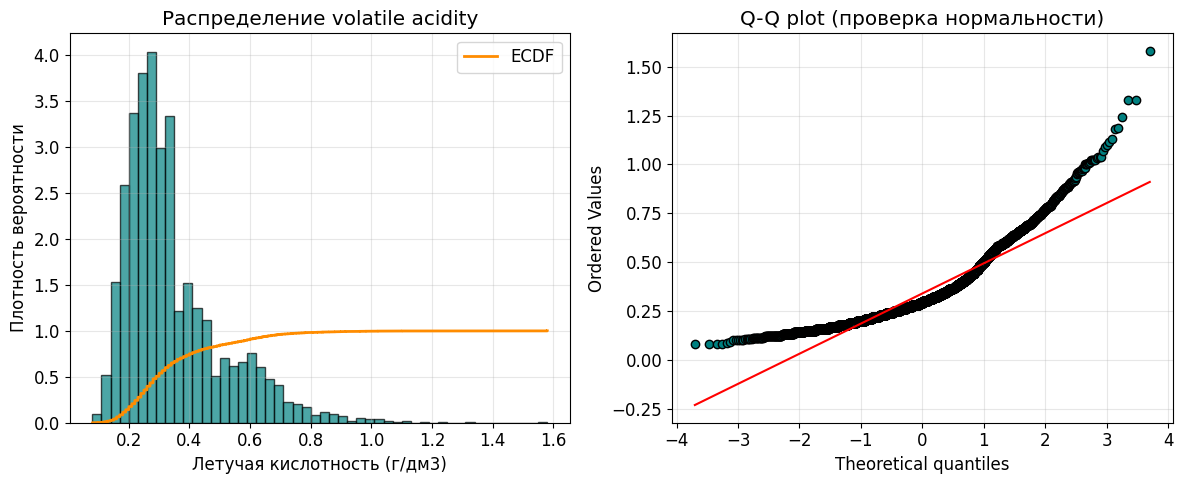

In [17]:
import seaborn as sns
import scipy.stats as stats

va = df['volatile acidity']

print("Описательные статистики volatile acidity:")
print(f"Среднее:        {va.mean():.4f}")
print(f"Медиана:        {va.median():.4f}")
print(f"Дисперсия:      {va.var():.4f}")
print(f"Стд. отклонение:{va.std():.4f}")
print(f"Асимметрия:     {stats.skew(va):.4f}")
print(f"Эксцесс:        {stats.kurtosis(va):.4f}")

normality_test = stats.normaltest(va)
print(f"\nТест нормальности D'Agostino-Pearson:")
print(f"Статистика: {normality_test.statistic:.4f}")
print(f"p-value:    {normality_test.pvalue:.6g}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.hist(va, bins=50, density=True, alpha=0.7, color='teal', edgecolor='black')
ax1.set_title("Распределение volatile acidity")
ax1.set_xlabel("Летучая кислотность (г/дм3)")
ax1.set_ylabel("Плотность вероятности")

x_sorted = np.sort(va)
y_ecdf = np.arange(1, len(x_sorted) + 1) / len(x_sorted)
ax1.step(x_sorted, y_ecdf, where='post', color='darkorange', linewidth=2, label='ECDF')
ax1.legend()

stats.probplot(va, dist="norm", plot=ax2)
ax2.set_title("Q-Q plot (проверка нормальности)")
ax2.get_lines()[0].set_markerfacecolor('teal')
ax2.get_lines()[0].set_markeredgecolor('black')

plt.tight_layout()
plt.show()

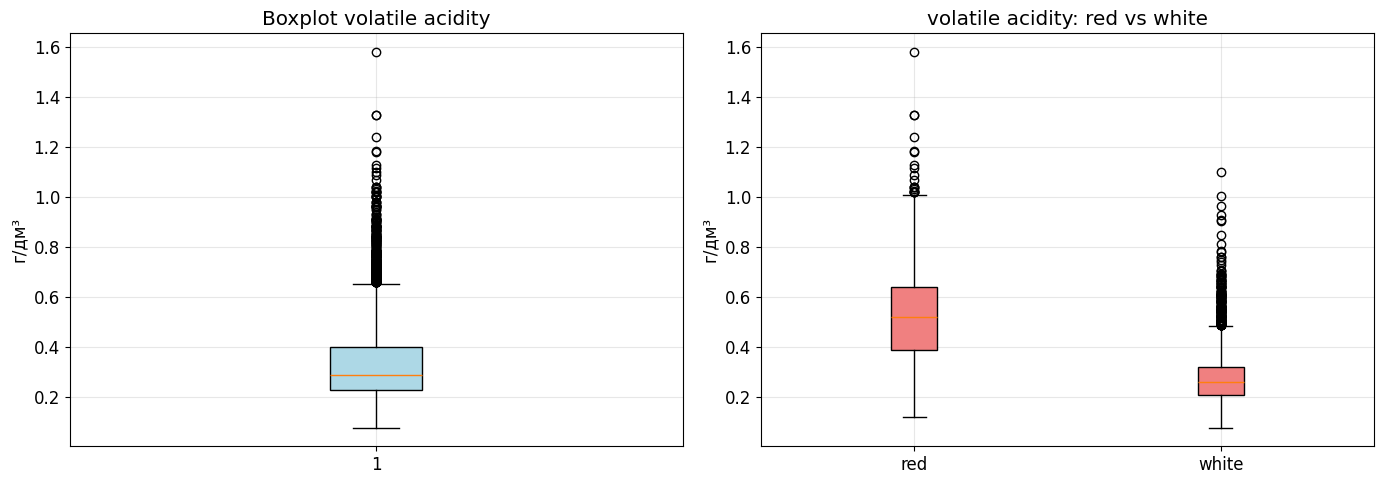

Красные: n=1599, mean=0.5278, median=0.5200
Белые:   n=4898, mean=0.2782, median=0.2600

Mann-Whitney U: U=7059623.5, p-value=0


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].boxplot(va, vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue'))
axes[0].set_title('Boxplot volatile acidity')
axes[0].set_ylabel('г/дм³')

va_red = df[df['color'] == 'red']['volatile acidity']
va_white = df[df['color'] == 'white']['volatile acidity']
axes[1].boxplot([va_red, va_white], tick_labels=['red', 'white'],
                patch_artist=True,
                boxprops=dict(facecolor='lightcoral'))
axes[1].set_title('volatile acidity: red vs white')
axes[1].set_ylabel('г/дм³')

plt.tight_layout()
plt.show()

print(f"Красные: n={len(va_red)}, mean={va_red.mean():.4f}, median={va_red.median():.4f}")
print(f"Белые:   n={len(va_white)}, mean={va_white.mean():.4f}, median={va_white.median():.4f}")

from scipy.stats import mannwhitneyu
u_stat, p_mw = mannwhitneyu(va_red, va_white, alternative='two-sided')
print(f"\nMann-Whitney U: U={u_stat:.1f}, p-value={p_mw:.6g}")

### Математическая база подобранных распределений

**Логнормальное** (случайная величина $X>0$, если $\ln X \sim \mathcal{N}(\mu, \sigma^2)$):

$$f(x; \mu, \sigma) = \frac{1}{x\sigma\sqrt{2\pi}} \exp\left(-\frac{(\ln x - \mu)^2}{2\sigma^2}\right)$$

Оценки МП: $\hat\mu = \overline{\ln x}$, $\hat\sigma^2 = \frac{1}{n}\sum (\ln x_i - \hat\mu)^2$. Хвост тяжелее нормального — хорошо подходит для скошенных положительных данных.

**Гамма** (сумма $k$ независимых $\mathrm{Exp}(\theta)$):

$$f(x; k, \theta) = \frac{x^{k-1} e^{-x/\theta}}{\theta^k \Gamma(k)}, \quad x>0$$

Оценки МП через численное решение уравнения для $k$ и $\theta = \bar x/k$. Параметр $k$ (форма) регулирует скошенность, $\theta$ (масштаб) — разброс.

**Выбор модели — критерий Акаике:** $\mathrm{AIC} = 2k - 2\ln \hat L$, штраф за число параметров. У обоих распределений $k=2$, поэтому сравнение по AIC эквивалентно сравнению логарифма правдоподобия.

Lognormal params: (np.float64(0.43901245106918074), 0, np.float64(0.30718848517614583))
  KS stat = 0.0630, p = 6.801e-23, AIC = -7592.1
Gamma params:     (5.135907429210994, 0, np.float64(0.06613553775527199))
  KS stat = 0.0943, p = 9.704e-51, AIC = -7105.2


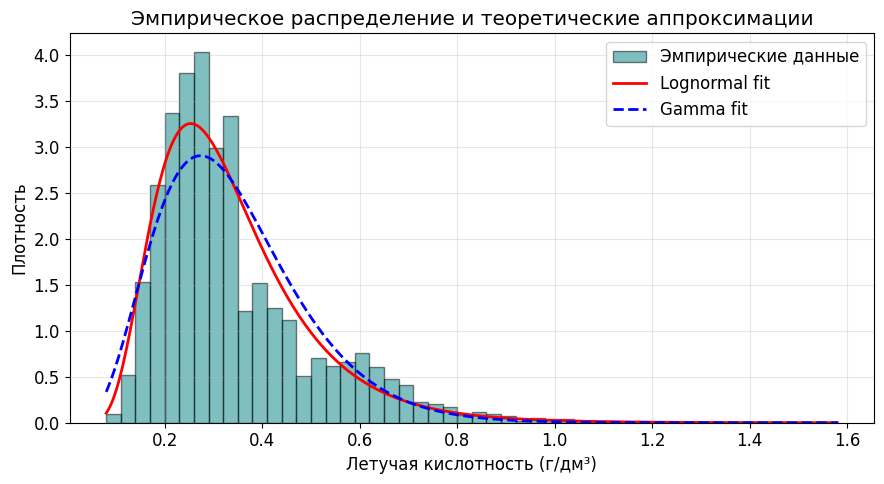

In [19]:
from scipy import stats as sps

va_arr = df['volatile acidity'].values

# Логнормальное (floc=0 — фиксируем нижнюю границу в 0)
ln_params = sps.lognorm.fit(va_arr, floc=0)
ln_ll = np.sum(sps.lognorm.logpdf(va_arr, *ln_params))
ln_aic = 2 * 2 - 2 * ln_ll   # k=2 (s, scale)

# Гамма (floc=0)
gm_params = sps.gamma.fit(va_arr, floc=0)
gm_ll = np.sum(sps.gamma.logpdf(va_arr, *gm_params))
gm_aic = 2 * 2 - 2 * gm_ll

# KS-тесты
ln_ks = sps.kstest(va_arr, 'lognorm', args=ln_params)
gm_ks = sps.kstest(va_arr, 'gamma',  args=gm_params)

print(f"Lognormal params: {ln_params}")
print(f"  KS stat = {ln_ks.statistic:.4f}, p = {ln_ks.pvalue:.4g}, AIC = {ln_aic:.1f}")
print(f"Gamma params:     {gm_params}")
print(f"  KS stat = {gm_ks.statistic:.4f}, p = {gm_ks.pvalue:.4g}, AIC = {gm_aic:.1f}")

# Наложим обе плотности на гистограмму
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(va_arr, bins=50, density=True, alpha=0.5,
        color='teal', edgecolor='black', label='Эмпирические данные')
x_grid = np.linspace(va_arr.min(), va_arr.max(), 400)
ax.plot(x_grid, sps.lognorm.pdf(x_grid, *ln_params),
        'r-', lw=2, label='Lognormal fit')
ax.plot(x_grid, sps.gamma.pdf(x_grid, *gm_params),
        'b--', lw=2, label='Gamma fit')
ax.set_xlabel('Летучая кислотность (г/дм³)')
ax.set_ylabel('Плотность')
ax.set_title('Эмпирическое распределение и теоретические аппроксимации')
ax.legend()
plt.tight_layout()
plt.show()

### EDA: Сравнение красных и белых вин

Боксплоты наглядно демонстрируют, что объединенная выборка неоднородна. Медиана летучей кислотности у красных вин (0.52 г/дм³) ровно в два раза выше, чем у белых (0.26 г/дм³). Это физически закономерно: красные вина проходят малолактическую ферментацию и дольше контактируют с мезгой, что способствует накоплению уксусной кислоты. Тест Манна-Уитни подтверждает, что распределения статистически значимо различаются ($U=7.06 \times 10^6$, $p \approx 0$).

Также мы видим множество выбросов в правом хвосте (вплоть до 1.58 г/дм³).

### Подгонка теоретических распределений

Для математического описания случайной величины были подобраны два популярных закона для строго положительных скошенных данных: логарифмически нормальное и гамма-распределение (методом максимального правдоподобия).

Визуально (см. график плотности) логнормальное распределение гораздо точнее описывает пик и правый хвост. Это подтверждается информационным критерием Акаике (AIC): для логнормального распределения $AIC = -7592.1$, что значительно ниже, чем у гамма-распределения ($AIC = -7105.2$).

Однако формальный критерий согласия Колмогорова-Смирнова (KS-тест) отвергает обе гипотезы ($p \approx 0$). При объеме выборки $N=6497$ KS-тест становится гиперчувствительным к малейшим отклонениям от идеальной теоретической кривой. Главная причина отклонения — **гетерогенность данных**: мы фитим единую кривую к смеси двух разных популяций (красные и белые вина), которые имеют разные параметры распределения. Кроме того, данные округлены до сотых, что создает дискретность.

Таким образом, для дальнейшего статистического анализа мы опираемся на эмпирическое распределение, используя логнормальный закон лишь как качественную аппроксимацию, наилучшим образом описывающую форму хвоста.

### Нормализация

Z-нормализация приводит volatile acidity к стандартному масштабу (μ=0, σ=1). Это стандартная процедура перед многомерными методами (PCA, k-NN, линейная регрессия), чувствительными к масштабу признаков. Важно понимать, что z-преобразование — это линейное аффинное преобразование: оно сдвигает и масштабирует, но не меняет форму распределения. Асимметрия и эксцесс остаются теми же, правосторонняя скошенность не изменяется. Для этого нужны нелинейные преобразования (логарифм, Бокс-Кокс). В дальнейшем анализе мы работаем с исходными значениями, поскольку физическая интерпретация (г/дм³ уксусной кислоты) удобнее в исходных единицах; нормализация здесь приведена как демонстрация приведения к стандартному масштабу.

После нормализации: mean = 0.000000, std = 1.000000


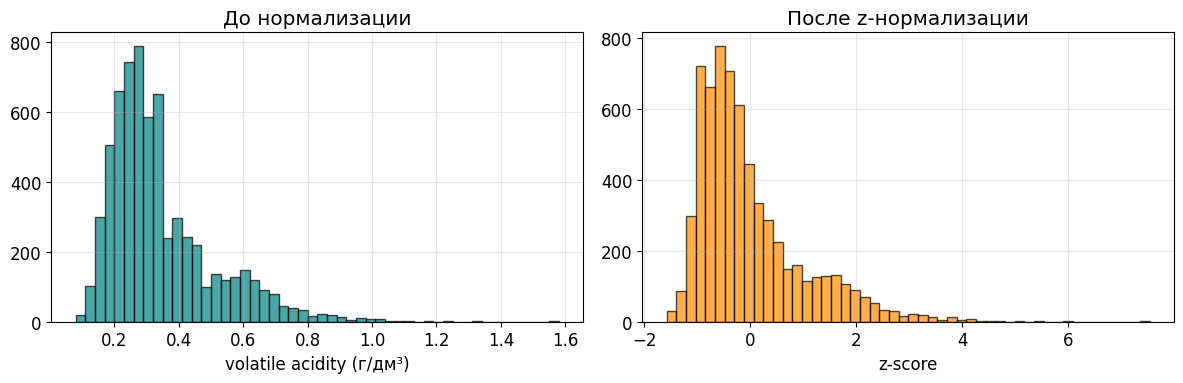

      n  Mean (with rep)  SD (with rep)  Mean (without rep)  SD (without rep)  \
0    10           0.3397         0.0510              0.3407            0.0527   
1    50           0.3400         0.0228              0.3389            0.0231   
2   100           0.3401         0.0164              0.3395            0.0163   
3   500           0.3396         0.0074              0.3398            0.0071   
4  1000           0.3396         0.0054              0.3399            0.0050   
5  2000           0.3397         0.0037              0.3398            0.0030   

   Theoretical SD  Rel. Error (%)  
0          0.0520          1.3341  
1          0.0232          0.2783  
2          0.0163          0.0281  
3          0.0071          0.8671  
4          0.0048          3.8663  
5          0.0031          1.6198  


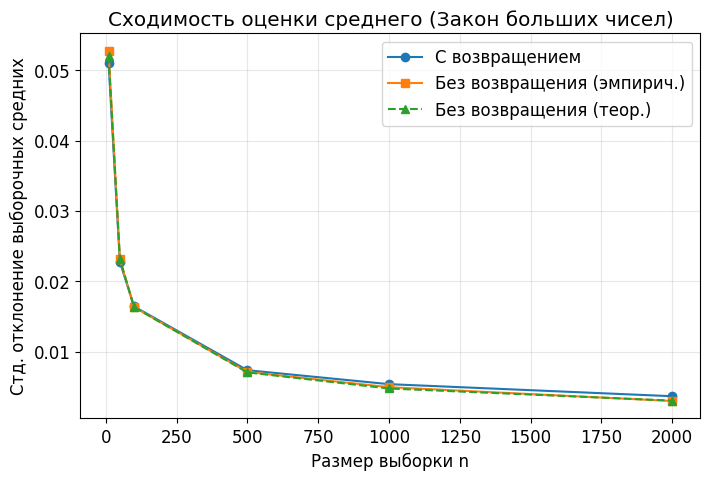


Истинное среднее по совокупности: 0.3397
Максимальная относительная ошибка SD: 3.87%


In [20]:
va_z = (va - va.mean()) / va.std(ddof=1)
print(f"После нормализации: mean = {va_z.mean():.6f}, std = {va_z.std(ddof=1):.6f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(va, bins=50, color='teal', alpha=0.7, edgecolor='black')
axes[0].set_title('До нормализации')
axes[0].set_xlabel('volatile acidity (г/дм³)')

axes[1].hist(va_z, bins=50, color='darkorange', alpha=0.7, edgecolor='black')
axes[1].set_title('После z-нормализации')
axes[1].set_xlabel('z-score')

plt.tight_layout()
plt.show()

pop = va.to_numpy()
pop_mean = pop.mean()
pop_var = pop.var(ddof=1)
N = len(pop)

sizes = [10, 50, 100, 500, 1000, 2000]
rows = []
rng = np.random.default_rng(42)

for n in sizes:
    means_with_rep = [rng.choice(pop, size=n, replace=True).mean() for _ in range(1000)]
    means_without_rep = [rng.choice(pop, size=n, replace=False).mean() for _ in range(1000)]

    sd_with = np.std(means_with_rep, ddof=1)
    sd_without = np.std(means_without_rep, ddof=1)
    sd_theor = np.sqrt((pop_var / n) * ((N - n) / (N - 1)))

    rel_error = abs(sd_without - sd_theor) / sd_theor * 100

    rows.append({
        "n": n,
        "Mean (with rep)": np.mean(means_with_rep),
        "SD (with rep)": sd_with,
        "Mean (without rep)": np.mean(means_without_rep),
        "SD (without rep)": sd_without,
        "Theoretical SD": sd_theor,
        "Rel. Error (%)": rel_error
    })

est_df = pd.DataFrame(rows)
print(est_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(est_df["n"], est_df["SD (with rep)"], marker='o', label="С возвращением")
plt.plot(est_df["n"], est_df["SD (without rep)"], marker='s', label="Без возвращения (эмпирич.)")
plt.plot(est_df["n"], est_df["Theoretical SD"], marker='^', linestyle='--', label="Без возвращения (теор.)")
plt.xlabel("Размер выборки n")
plt.ylabel("Стд. отклонение выборочных средних")
plt.title("Сходимость оценки среднего (Закон больших чисел)")
plt.legend()
plt.show()

print(f"\nИстинное среднее по совокупности: {pop_mean:.4f}")
print(f"Максимальная относительная ошибка SD: {est_df['Rel. Error (%)'].max():.2f}%")

### Independence & Estimations: состоятельность оценок

Выборочное среднее демонстрирует состоятельность как оценка математического ожидания. При росте объёма выборки от 10 до 2000 наблюдений стандартное отклонение выборочных средних монотонно убывает с 0.051 до 0.003, что качественно согласуется с теоретической зависимостью σ/√n. Все выборочные средние лежат в окрестности истинного значения 0.3397, систематического отклонения от истины не наблюдается.

Сравнение схем сэмплирования с возвращением и без показывает, что при n ≪ N (максимальное n=2000 при N=6497) разница между двумя схемами невелика и сравнима с шумом Монте-Карло. Эмпирическое стандартное отклонение при отборе без возвращения хорошо согласуется с теоретической формулой σ√((N- n)/(N - 1)): относительная ошибка в таблице лежит в диапазоне 0.03%–3.87% в зависимости от n.

Обратим внимание на немонотонность относительной ошибки: она минимальна при n=100 и максимальна при n=1000. Это не статистическая проблема, а артефакт конечного числа повторений: при больших n истинная SD становится малой (≈0.003), и та же абсолютная ошибка Монте-Карло даёт большой относительный вклад. Абсолютная ошибка при этом монотонно падает. Увеличение числа повторений сгладило бы эту немонотонность.

Таким образом, состоятельность оценки математического ожидания подтверждена эмпирически.

Дисперсии всех числовых признаков (топ-5):


,0
total sulfur dioxide,3194.72
free sulfur dioxide,315.04
residual sugar,22.64
fixed acidity,1.68
alcohol,1.42


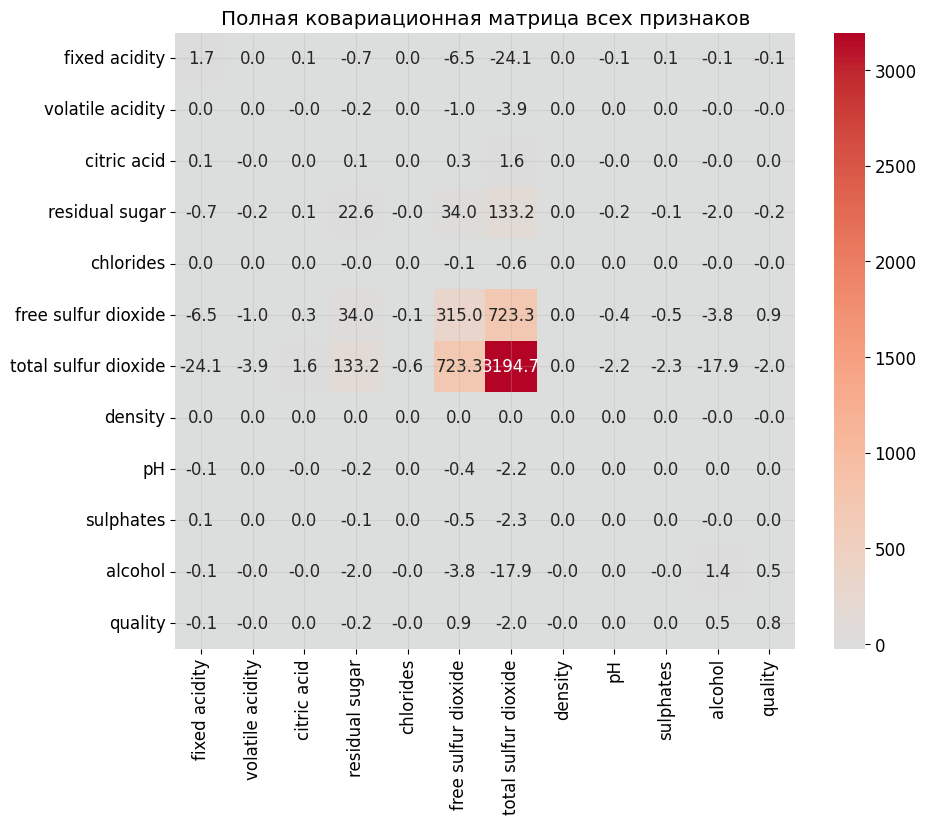


Ковариационная матрица 2x2 для выбранных признаков:


,free sulfur dioxide,total sulfur dioxide
free sulfur dioxide,315.04,723.26
total sulfur dioxide,723.26,3194.72


In [21]:
numeric_df = df.select_dtypes(include='number')
variances = numeric_df.var().sort_values(ascending=False)

print("Дисперсии всех числовых признаков (топ-5):")
display(variances.head(5).to_frame().style.format("{:.2f}"))

cov_full = numeric_df.cov()
plt.figure(figsize=(10, 8))
sns.heatmap(cov_full, annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Полная ковариационная матрица всех признаков")
plt.show()

X = df['free sulfur dioxide']
Y = df['total sulfur dioxide']

cov_matrix_2x2 = np.cov(X, Y, ddof=1)

print("\nКовариационная матрица 2x2 для выбранных признаков:")
display(pd.DataFrame(
    np.round(cov_matrix_2x2, 2),
    index=["free sulfur dioxide", "total sulfur dioxide"],
    columns=["free sulfur dioxide", "total sulfur dioxide"]
))

Наибольшей дисперсией обладают total sulfur dioxide (3194.72) и free sulfur dioxide (315.04). Следующий по величине — residual sugar (22.64), затем fixed acidity (1.68) и alcohol (1.42). Разрыв между первой парой и остальными признаками больше чем на порядок, поэтому для двумерного ковариационного анализа выбраны именно free и total SO₂.

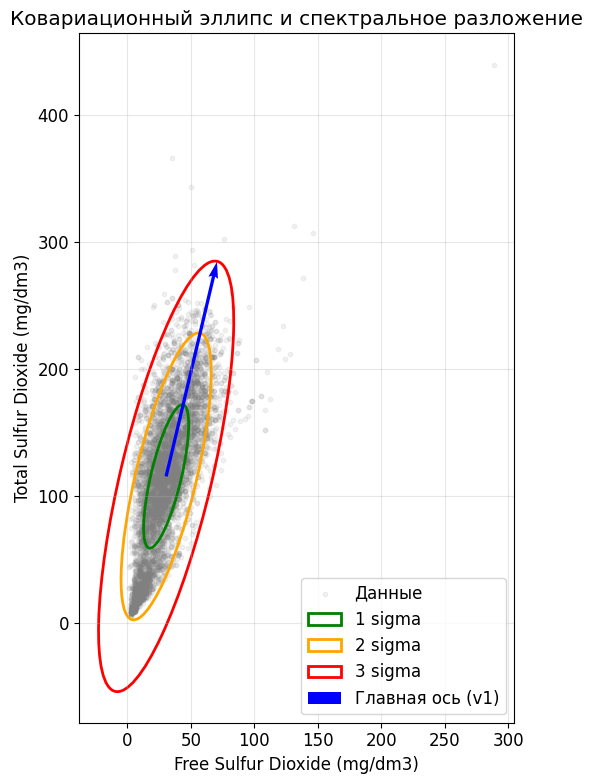

Собственные значения: lambda_1 = 3366.17, lambda_2 = 143.59
Доля дисперсии первой компоненты: 95.9%
Угол главной оси: 76.7°
Главный собственный вектор: [0.23065565 0.97303544]


In [22]:
def plot_confidence_ellipse(ax, cov, center, n_std, **kwargs):
    evals, evecs = np.linalg.eigh(cov)
    evals = evals[::-1]
    evecs = evecs[:, ::-1]

    scale = n_std

    width = 2 * np.sqrt(evals[0]) * scale
    height = 2 * np.sqrt(evals[1]) * scale
    angle = np.degrees(np.arctan2(evecs[1, 0], evecs[0, 0]))

    ellipse = patches.Ellipse(center, width, height, angle=angle, fill=False, **kwargs)
    ax.add_patch(ellipse)
    return angle, evecs[:, 0]

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(X, Y, alpha=0.1, s=10, color='gray', label='Данные')

angle_deg, main_axis_vec = plot_confidence_ellipse(ax, cov_matrix_2x2, (X.mean(), Y.mean()), n_std=1, edgecolor='green', linewidth=2, label='1 sigma')
plot_confidence_ellipse(ax, cov_matrix_2x2, (X.mean(), Y.mean()), n_std=2, edgecolor='orange', linewidth=2, label='2 sigma')
plot_confidence_ellipse(ax, cov_matrix_2x2, (X.mean(), Y.mean()), n_std=3, edgecolor='red', linewidth=2, label='3 sigma')

data_range = max(X.max() - X.min(), Y.max() - Y.min())
scale_vec = data_range * 0.4
ax.quiver(X.mean(), Y.mean(), main_axis_vec[0]*scale_vec, main_axis_vec[1]*scale_vec,
          color='blue', angles='xy', scale_units='xy', scale=1, label='Главная ось (v1)')

ax.set_xlabel("Free Sulfur Dioxide (mg/dm3)")
ax.set_ylabel("Total Sulfur Dioxide (mg/dm3)")
ax.set_title("Ковариационный эллипс и спектральное разложение")
ax.legend()
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

evals_final, _ = np.linalg.eigh(cov_matrix_2x2)
evals_final = evals_final[::-1]
print(f"Собственные значения: lambda_1 = {evals_final[0]:.2f}, lambda_2 = {evals_final[1]:.2f}")
print(f"Доля дисперсии первой компоненты: {evals_final[0] / np.sum(evals_final) * 100:.1f}%")
print(f"Угол главной оси: {angle_deg:.1f}°")
print(f"Главный собственный вектор: {main_axis_vec}")

Спектральное разложение ковариационной матрицы дало собственные значения $\lambda_1 = 3366.17$ и $\lambda_2 = 143.59$. Первая главная компонента объясняет 95.9% общей дисперсии, что указывает на сильную вытянутость облака точек вдоль одной оси. Угол наклона главной оси составляет 76.7°, что согласуется с доминированием дисперсии по оси total sulfur dioxide.

*Примечание:* Вероятностная интерпретация эллипсов (1$\sigma$ $\approx$ 39.3% и т.д.) строго верна только для двумерного нормального распределения. Поскольку маргинальные распределения этих признаков не являются строго нормальными, эллипсы используются здесь преимущественно как визуальный инструмент для демонстрации ковариационной структуры и главных направлений изменчивости.

In [24]:
print("Проверка нормальности (D'Agostino-Pearson):")
for col in ['free sulfur dioxide', 'total sulfur dioxide']:
    s = df[col]
    stat, p = stats.normaltest(s)
    print(f"  {col}: skew={stats.skew(s):.2f}, p={p:.3g}")

for color in ['red', 'white']:
    sub = df[df['color'] == color]
    r_sub, p_sub = stats.pearsonr(sub['free sulfur dioxide'], sub['total sulfur dioxide'])
    print(f"Пирсон для {color}: r={r_sub:.4f}, p={p_sub:.3g}")

r, p = stats.pearsonr(df['free sulfur dioxide'], df['total sulfur dioxide'])
print(f"\nОбщий Пирсон: r={r:.4f}, p={p:.3g}")
print("Примечание: p-value = 0 в float64 — истинное p << 1e-300.")


r = corr_result.statistic
p_value = corr_result.pvalue
n_samples = len(df)

t_stat_manual = (r * np.sqrt(n_samples - 2)) / np.sqrt(1 - r**2)

print(f"Коэффициент корреляции Пирсона (r): {r:.4f}")
print(f"t-статистика: {t_stat_manual:.4f}")
print(f"Степени свободы: {n_samples - 2}")
print(f"p-value: {p_value:.6g}")

if p_value < 0.05:
    print("\nВывод: p-value < 0.05. Нулевая гипотеза H0 отвергается.")
    print("Существует статистически значимая линейная зависимость между свободным и общим диоксидом серы.")
else:
    print("\nВывод: p-value >= 0.05. Нет оснований отвергать H0.")

Проверка нормальности (D'Agostino-Pearson):
  free sulfur dioxide: skew=1.22, p=0
  total sulfur dioxide: skew=-0.00, p=4.21e-13
Пирсон для red: r=0.6677, p=6.4e-207
Пирсон для white: r=0.6155, p=0

Общий Пирсон: r=0.7209, p=0
Примечание: p-value = 0 в float64 — истинное p << 1e-300.
Коэффициент корреляции Пирсона (r): 0.7209
t-статистика: 83.8397
Степени свободы: 6495
p-value: 0

Вывод: p-value < 0.05. Нулевая гипотеза H0 отвергается.
Существует статистически значимая линейная зависимость между свободным и общим диоксидом серы.


free SO₂ и total SO₂ связаны структурно (total=free+bound), так что их зависимость была очевидна

## Lab resume

### Что исследовалось
Случайная величина volatile acidity из датасета Wine Quality (Cortez et al., 2009). Объединенная выборка: 6497 наблюдений.

### Основные результаты
- **Распределение:** Положительная асимметрия (1.49), тяжелый правый хвост. Гипотеза о нормальности отвергается (D'Agostino-Pearson, p = 0).
- **Состоятельность оценок:** Эмпирически подтверждена для выборочного среднего. Стандартное отклонение средних убывает пропорционально $1/\sqrt{n}$, максимальная относительная ошибка между эмпирическим и теоретическим стандартным отклонением (с поправкой на конечность) не превышает 4%
- **Ковариационный анализ:** Выделены два признака с наибольшей дисперсией (free и total sulfur dioxide). Спектральное разложение их ковариационной матрицы показало, что первая главная компонента объясняет 95.9% дисперсии.
- **Проверка гипотез:** Проверена гипотеза о линейной зависимости между свободным и общим диоксидом серы ($H_0: \rho = 0$). Получено $r = 0.721$, $t = 83.84$, $p < 10^{-16}$. $H_0$ отвергается. Зависимость статистически значима и физически обоснована ($total = free + bound$).

### References
1. Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems*, 47(4), 547-553. https://doi.org/10.1016/j.dss.2009.05.016